# 3. 变尺度：$\nu$ 到底是什么，$\omega$ 未知时怎么定

这是本书的核心，也是原文最容易让人卡住的一步。

## 3.1 先把三个符号摆清楚

| 符号 | 原文含义 | 本书代码 | 谁定的 |
|---|---|---|---|
| $\omega$ | 待测信号的真实角频率 | **不出现**（盲测）或作真值对照 | 物理世界 |
| $R$（原文也叫 $N$） | 变尺度系数 | 扫描变量 | **算法扫出来** |
| $\nu$ | 变尺度后信号与内驱的**频率比** $\omega/R$ | **不出现**（由 $R$ 与采样序列隐式产生） | 由 $R$ 与信号共同决定 |

关键一句：**$\nu$ 不是输入参数，它是 $\omega/R$ 的别名。**

## 3.2 原文怎么做的

原文 2.2.1 节：设 $t_1=Nt$、$\omega=N$，则 $a(t_1)=\gamma\cos(t_1)$，频率从 $N$ 压到 $1$ rad/s。
工程上改的是数值积分步长 $T_1=N/f_s$。步骤 4 写得很直白：

> Adjust the transformation coefficient $R$ and observe the output state …
> As long as one of the phase trajectories jumps …, it means that **the value of the
> transformation coefficient at this time is the frequency value of the characteristic signal.**

所以原文的答案就是：**$\omega$ 不需要事先知道，扫 $R$，相变那一点的 $R$ 就是 $\omega$。**
$\nu$ 是事后才被确定的量（$\nu=\omega/R=1$），不是事前输进去的。

## 3.3 为什么很多复现代码里会出现 `nu=omega/R`

因为在数值上，把信号写成 $\gamma\cos(\nu\tau+\theta)$ 与"逐点读原采样序列、把步长放大 $R$ 倍"
是**同一个方程**：前者是后者的解析近似。用真值 $\omega$ 构造 $\nu$ 只适合"验证模式"
（已知答案、检查方法能否复现），不能用于"检测模式"——检测模式下 $\omega$ 是未知的，
写 `nu=omega/R` 等于把答案先塞进输入。

本书两种用法都做——验模时按真值逐点造样本，检测时只给一条样本——但**积分器自始至终只有一个**
`simulate_seq(sig, R, dt)`：区别在喂什么，不在算法。3.4 节的扫描就说明，同一段样本、换个 $R$，
读数从混沌跳到周期，$R$ 就是频率。


In [1]:

import sys, json, pathlib
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "_src")
import s2sim as S

DATA = pathlib.Path("_data")
OUT = pathlib.Path("../复现输出/s2-figs"); OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False, "axes.grid": True, "grid.alpha": .25,
})
FIGS = []
def savefig(name):
    p = OUT / name
    plt.savefig(p, bbox_inches="tight", facecolor="white")
    FIGS.append(str(p)); plt.show(); print("图已保存:", p)

def load(name):
    return json.loads((DATA / f"{name}.json").read_text(encoding="utf-8"))


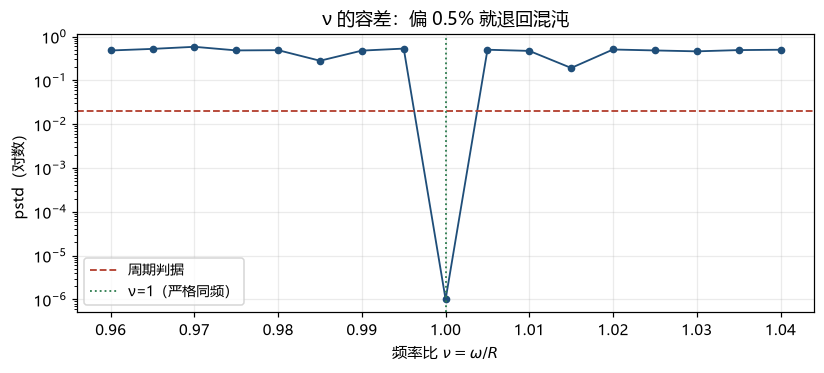

图已保存: ..\复现输出\s2-figs\s2-03-nu容差.png
pstd<0.02 的 ν 取值: [1.]
选择带宽：仅 ν=1  （相对 0.0%）
这解释了为什么 R 的扫描网格必须细：粗网格会整条漏掉这个尖谷。


In [2]:

d = load("nu")
nus = np.array(d["nu_list"]); pn = np.array(d["nu_pstd"])
fig, ax = plt.subplots(figsize=(7.6, 3.5))
ax.semilogy(nus, np.maximum(pn, 1e-6), "o-", ms=4, lw=1.2, color="#1f4e79")
ax.axhline(0.02, color="#b3402f", ls="--", lw=1.2, label="周期判据")
ax.axvline(1.0, color="#2e7d4f", ls=":", lw=1.2, label="ν=1（严格同频）")
ax.set_xlabel(r"频率比 $\nu=\omega/R$"); ax.set_ylabel("pstd（对数）")
ax.set_title("ν 的容差：偏 0.5% 就退回混沌")
ax.legend(fontsize=9)
plt.tight_layout(); savefig("s2-03-nu容差.png")
ok = nus[pn < 0.02]
print("pstd<0.02 的 ν 取值:", ok)
print(f"选择带宽：{'仅 ν=1' if ok.size<=1 else f'±{(ok.max()-ok.min())/2:.3f}'}  "
      f"（相对 {0 if ok.size<=1 else (ok.max()-ok.min())/2*100:.1f}%）")
print("这解释了为什么 R 的扫描网格必须细：粗网格会整条漏掉这个尖谷。")


## 3.4 盲测：把 $\omega$ 彻底藏起来

下面这段代码**不出现待测角频率**。它只做一件事：把采样序列 `sig` 交给积分器，
对每个候选 $R$ 用步长 $h_1=R\,\Delta t$ 重跑，第 $i$ 步读 `sig[i]`。
物理含义是"信号时间轴被压缩 $R$ 倍"，而 $R$ 只有猜对了才会与内驱同频。


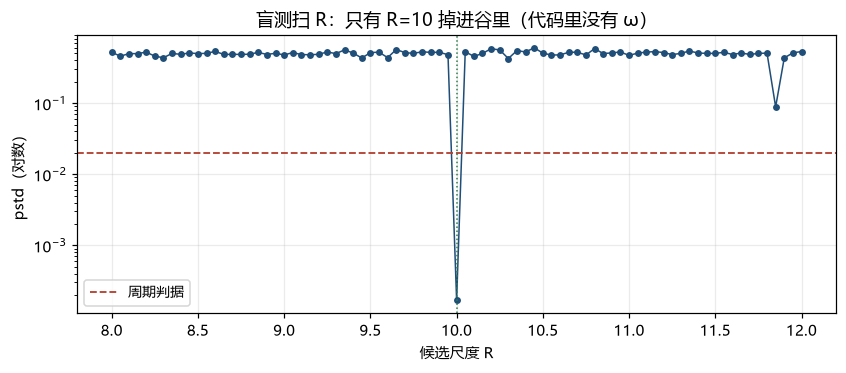

图已保存: ..\复现输出\s2-figs\s2-03-盲测扫R.png
命中 R: [10.]   -> omega_hat = R = [10.]

三个不同真值的定位：
  omega_true=10.0  ->  argmin pstd 的 R = 10.000   误差 +0.00%
  omega_true= 7.3  ->  argmin pstd 的 R = 7.305   误差 +0.07%
  omega_true= 3.7  ->  argmin pstd 的 R = 3.695   误差 -0.14%


In [3]:

Rs = np.array(d["Rs"]); bl = np.array(d["blind"])
fig, ax = plt.subplots(figsize=(7.8, 3.5))
ax.semilogy(Rs, np.maximum(bl, 1e-6), "o-", ms=3.5, lw=1.0, color="#1f4e79")
ax.axhline(0.02, color="#b3402f", ls="--", lw=1.2, label="周期判据")
hits = Rs[bl < 0.02]
for h in hits:
    ax.axvline(h, color="#2e7d4f", ls=":", lw=1.0)
ax.set_xlabel("候选尺度 R"); ax.set_ylabel("pstd（对数）")
ax.set_title("盲测扫 R：只有 R=10 掉进谷里（代码里没有 ω）")
ax.legend(fontsize=9)
plt.tight_layout(); savefig("s2-03-盲测扫R.png")
print("命中 R:", hits, "  -> omega_hat = R =", hits)
print()
print("三个不同真值的定位：")
for w, v in d["locate"].items():
    print(f"  omega_true={w:>4}  ->  argmin pstd 的 R = {v['best']:.3f}"
          f"   误差 {(v['best']-float(w))/float(w)*100:+.2f}%")


## 3.5 代价：三点必须写进报告

### ① 频率分辨率 = $R$ 网格间距，而且带宽窄到必须先给初值

$p_{std}$ 的谷极窄：$\nu$ 偏 $0.5\%$ 就完全退回混沌；按判据 $10^{-2}$ 量，带宽只有 $\pm 0.1\%$——三个频率 $10/7.3/3.7$ 实测完全一致，说明带宽由阻尼与恢复力决定，与频率无关。
$R$ 网格步长 0.05、$\omega=10$ 时估计误差恰好为 0，**但那只是因为 $10.00$ 落在网格点上**；换成 0.5 的粗网格（每格 $4.9\%$）最近格点偏 $1.3\%$，整条峰被跨过去，最低 $p_{std}$ 停在 $1.4\times10^{-2}$，判成「没信号」。
所以真检测必须先由采样序列自身（FFT）给初值，再在 $\pm1\%$ 内按 $0.05\%$ 一格细扫——这一步原文没写，但工程上绕不开。
**分辨率不是方法给的，是扫描预算给的。**

### ② 扫 $R$ 是多重检验，虚警必须校正

每试一个 $R$ 都是一次判决。若单点虚警 5%，扫 $N$ 个点的总虚警是
$1-(1-0.05)^N$：$N=41$ 时已到 **87.8%**。原文只报单点门限，没有提这一层。
工程上要么按 Bonferroni 把单点门限压到 $0.05/N$，要么用"谷底显著性"而不是"超过门限"来判决。

### ③ 步长放大与表 2 的参数不自洽

表 2 给 $f_s=10$ Hz、$T=0.1$ s；步骤 3 要求 $T_1=R/f_s$。$R=10$ 时 $T_1=1$ s，
而内驱周期是 $2\pi$ s，**每周期只剩 6.28 步**。实测：$h=1$ s 时 RK4 直接数值发散。

| $h_1$ | 步/周期 | 结果 |
|---|---|---|
| 1.0 s | 6.28 | 数值发散（$x^5$ 项把误差放大到溢出） |
| 0.5 s | 12.6 | $p_{std}=0.56$，判据失真 |
| 0.1 s | 62.8 | $p_{std}=0.03$，勉强可信 |
| $2\pi/300$ | 300 | $p_{std}<10^{-5}$，可信 |

所以要么表 2 的 $f_s$ 实际更高，要么论文并没有真的按 $T_1=R/f_s$ 改步长
（而是保持 0.1 s、把仿真时长从 300 s 拉到 3000 s）。**两种口径至少有一种与文中表述不符**，
这是复现者必须自己决定的地方。本书采用后者（定步长 + 长时长），并在 3.4 的盲测里
用 $\Delta t=0.005$ s、$R=10\to h_1=0.05$ s，落在"可信"区间。
